## EV Charging and Battery Intelligence: End-to-End Exploratory Data Analysis

This notebook explores the **EV Charging and Battery Intelligence Dataset** published by Mobeen Fatimah on Kaggle. It is designed to run directly in Kaggle or locally after updating the data path.

The workflow covers dataset discovery, data quality, descriptive statistics, charging and battery-related patterns, visual analysis, and an optional lightweight baseline model when a suitable target column is available.

**Important:** The notebook detects column names from the uploaded files instead of assuming a fixed schema. Interpret findings in the context of the actual dataset and its documentation.

## 1. Import Libraries

In [1]:
# 1. Import libraries and set notebook-wide options
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 10

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Locate the dataset files

On Kaggle, attached datasets are normally available under `/kaggle/input`. This cell searches that directory recursively for common tabular formats. If running locally, set `LOCAL_DATA_DIR` to the folder containing your downloaded dataset.

In [2]:
KAGGLE_INPUT = Path("/kaggle/input")
LOCAL_DATA_DIR = None  # Example: Path(r"C:\Users\User\Downloads\ev-dataset")

if KAGGLE_INPUT.exists():
    DATA_ROOT = KAGGLE_INPUT
elif LOCAL_DATA_DIR is not None and Path(LOCAL_DATA_DIR).exists():
    DATA_ROOT = Path(LOCAL_DATA_DIR)
else:
    DATA_ROOT = Path.cwd()

supported_extensions = {".csv", ".parquet", ".xlsx", ".xls"}
data_files = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in supported_extensions
)

print(f"Search location: {DATA_ROOT.resolve()}")
print(f"Tabular files found: {len(data_files)}")
for file_path in data_files[:50]:
    print(f"- {file_path}")

Search location: /kaggle/input
Tabular files found: 6
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_battery_health.csv
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_charging_sessions.csv
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_charging_stations.csv
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_charging_telemetry.csv
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_station_hourly_demand.csv
- /kaggle/input/datasets/mobeenfatimah/ev-charging-and-battery-intelligence-dataset/ev_vehicles.csv


## 3. Load a data file

The loader supports CSV, Parquet, and Excel files. If the dataset contains multiple tables, the notebook chooses the largest table by row count for the main analysis; all discovered files remain listed above so you can adapt the workflow for related tables.

In [3]:
def read_table(path):
    suffix = path.suffix.lower()
    if suffix == ".csv":
        # Try common encodings; pandas infers delimiters using the default comma.
        try:
            return pd.read_csv(path, low_memory=False)
        except UnicodeDecodeError:
            return pd.read_csv(path, low_memory=False, encoding="latin-1")
    if suffix == ".parquet":
        return pd.read_parquet(path)
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    raise ValueError(f"Unsupported file type: {suffix}")

loaded_tables = {}
for path in data_files:
    try:
        loaded_tables[str(path)] = read_table(path)
        print(f"Loaded: {path.name} | shape={loaded_tables[str(path)].shape}")
    except Exception as exc:
        print(f"Skipped {path.name}: {exc}")

if not loaded_tables:
    raise FileNotFoundError(
        "No readable tabular files found. Attach the Kaggle dataset to the notebook "
        "or set LOCAL_DATA_DIR to the folder containing its files."
    )

main_path = max(loaded_tables, key=lambda key: loaded_tables[key].shape[0])
df_raw = loaded_tables[main_path].copy()
print("\nSelected main table:", Path(main_path).name)
print("Raw shape:", df_raw.shape)

Loaded: ev_battery_health.csv | shape=(100000, 9)
Loaded: ev_charging_sessions.csv | shape=(250000, 18)
Loaded: ev_charging_stations.csv | shape=(500, 10)
Loaded: ev_charging_telemetry.csv | shape=(1039402, 7)
Loaded: ev_station_hourly_demand.csv | shape=(250000, 7)
Loaded: ev_vehicles.csv | shape=(10000, 12)

Selected main table: ev_charging_telemetry.csv
Raw shape: (1039402, 7)


## 4. Inspect the first rows

Previewing the records helps establish what each row represents—for example, a charging session, a vehicle, a battery measurement, or an aggregated observation. Avoid interpreting individual column names until you have checked the dataset description.

In [4]:
display(df_raw.head(10))
print("\nRandom sample:")
display(df_raw.sample(min(5, len(df_raw)), random_state=RANDOM_STATE))

,session_id,vehicle_id,station_id,elapsed_minutes,soc_pct,charging_power_kw,battery_temperature_c
0,SES_0000001,EV_08728,STN_0284,0.000,17.870,6.660,12.500
1,SES_0000001,EV_08728,STN_0284,12.200,20.120,6.660,12.900
2,SES_0000001,EV_08728,STN_0284,24.500,22.370,6.660,13.300
3,SES_0000001,EV_08728,STN_0284,36.700,24.620,6.660,13.700
4,SES_0000001,EV_08728,STN_0284,48.900,26.880,6.660,14.100
5,SES_0000001,EV_08728,STN_0284,61.200,29.130,6.660,14.500
6,SES_0000001,EV_08728,STN_0284,73.400,31.380,6.660,14.900
7,SES_0000001,EV_08728,STN_0284,85.600,33.630,6.660,15.300
8,SES_0000001,EV_08728,STN_0284,97.800,35.880,6.660,15.700
9,SES_0000001,EV_08728,STN_0284,110.100,38.130,6.660,16.100



Random sample:


,session_id,vehicle_id,station_id,elapsed_minutes,soc_pct,charging_power_kw,battery_temperature_c
770287,SES_0037065,EV_03314,STN_0290,18.000,81.130,110.780,19.400
886321,SES_0042654,EV_02204,STN_0143,107.400,35.270,8.010,22.900
573036,SES_0027621,EV_02719,STN_0221,69.200,73.070,16.080,22.000
752608,SES_0036232,EV_04938,STN_0448,21.700,77.330,101.090,18.200
144924,SES_0006964,EV_05184,STN_0283,35.800,39.150,8.420,26.100


## 5. Review dimensions, column names, and data types

The number of rows and columns gives a first sense of dataset scale. The type summary also helps identify numeric measurements, categories, identifiers, and potential timestamps.

In [5]:
print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")
print("\nColumn names:")
for i, col in enumerate(df_raw.columns, start=1):
    print(f"{i:>3}. {col}")

schema = pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "non_null": df_raw.notna().sum().values,
    "null_count": df_raw.isna().sum().values,
    "null_percent": (df_raw.isna().mean().values * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True).values
})
display(schema.sort_values(["null_percent", "column"], ascending=[False, True]))

Rows: 1,039,402
Columns: 7

Column names:
  1. session_id
  2. vehicle_id
  3. station_id
  4. elapsed_minutes
  5. soc_pct
  6. charging_power_kw
  7. battery_temperature_c


,column,dtype,non_null,null_count,null_percent,unique_values
6,battery_temperature_c,float64,1039402,0,0.000,800
5,charging_power_kw,float64,1039402,0,0.000,14980
3,elapsed_minutes,float64,1039402,0,0.000,9367
0,session_id,object,1039402,0,0.000,50000
4,soc_pct,float64,1039402,0,0.000,9001
2,station_id,object,1039402,0,0.000,500
1,vehicle_id,object,1039402,0,0.000,9934


## 6. Measure missing values

Missingness can indicate optional sensors, incomplete charging sessions, data collection gaps, or fields that are not applicable to every record. The table and chart focus on columns that contain at least one missing value.

In [6]:

# Missing Values Analysis

# Ensure the DataFrame exists
if "df" not in globals():
    if "df_raw" in globals():
        df = df_raw.copy()
    else:
        from pathlib import Path
        import pandas as pd

        data_files = list(Path("/kaggle/input").rglob("*.csv"))

        if not data_files:
            raise FileNotFoundError(
                "No CSV dataset found. Attach your dataset using Kaggle's Add Input option."
            )

        df = pd.read_csv(data_files[0], low_memory=False)

        print(f"Loaded dataset: {data_files[0].name}")

# Calculate missing values
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

missing_nonzero = missing[missing["missing_count"] > 0]

display(
    missing_nonzero
    if not missing_nonzero.empty
    else pd.DataFrame({"message": ["No missing values detected."]})
)

# Visualize missing values
if not missing_nonzero.empty:
    plot_data = missing_nonzero.head(20).sort_values("missing_percent")

    ax = plot_data["missing_percent"].plot(
        kind="barh",
        figsize=(10, max(4, 0.32 * len(plot_data)))
    )

    ax.set_title("Columns with the Most Missing Values")
    ax.set_xlabel("Missing Values (%)")
    ax.set_ylabel("Column")

    plt.tight_layout()
    plt.show()
else:
    print("Missing-value chart skipped because there are no missing values.")

,message
0,No missing values detected.


Missing-value chart skipped because there are no missing values.


## 7. Summarize numeric variables

Numeric summaries reveal typical values, spread, and potential outliers. For EV charging and battery data, numeric fields may include energy, power, duration, voltage, current, temperature, state of charge, or battery health—but the exact fields depend on the dataset schema.

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print(f"Numeric columns: {len(numeric_cols)}")
print(f"Categorical/text columns: {len(categorical_cols)}")

if numeric_cols:
    display(df[numeric_cols].describe().T)
else:
    print("No numeric columns were detected.")

Numeric columns: 4
Categorical/text columns: 3


,count,mean,std,min,25%,50%,75%,max
elapsed_minutes,"1,039,402.000",164.517,148.332,0.000,47.500,127.000,241.700,"1,426.200"
soc_pct,"1,039,402.000",57.406,19.823,10.000,42.520,57.830,73.130,100.000
charging_power_kw,"1,039,402.000",15.550,25.837,5.000,5.910,7.730,9.150,297.430
battery_temperature_c,"1,039,402.000",30.263,10.642,-15.000,23.100,30.300,37.500,66.600


## 8. Explore categorical variables

Categorical fields can describe charger types, vehicle groups, charging modes, locations, or status labels. High-cardinality columns may be identifiers, so the notebook limits each displayed frequency table to the most common values.

In [8]:
if categorical_cols:
    for col in categorical_cols[:12]:
        print(f"\n{col} — {df[col].nunique(dropna=True)} unique values")
        display(df[col].value_counts(dropna=False).head(10).rename_axis(col).to_frame("count"))
else:
    print("No categorical/text columns were detected.")


session_id — 50000 unique values


,count
session_id,
SES_0049984,30
SES_0049982,30
SES_0049981,30
SES_0049979,30
SES_0049977,30
SES_0049976,30
SES_0049975,30
SES_0049970,30
SES_0000031,30



vehicle_id — 9934 unique values


,count
vehicle_id,
EV_09436,397
EV_09619,347
EV_08272,345
EV_09614,338
EV_02702,336
EV_01357,330
EV_04647,318
EV_00234,313
EV_00070,311



station_id — 500 unique values


,count
station_id,
STN_0403,4098
STN_0224,3895
STN_0450,3592
STN_0088,3542
STN_0242,3531
STN_0469,3507
STN_0423,3487
STN_0308,3469
STN_0255,3457


## 9. Visualize numeric distributions

Histograms make skew, multiple peaks, and implausible ranges easier to spot. A maximum of six numeric fields is shown to keep the notebook lightweight and the figures readable.

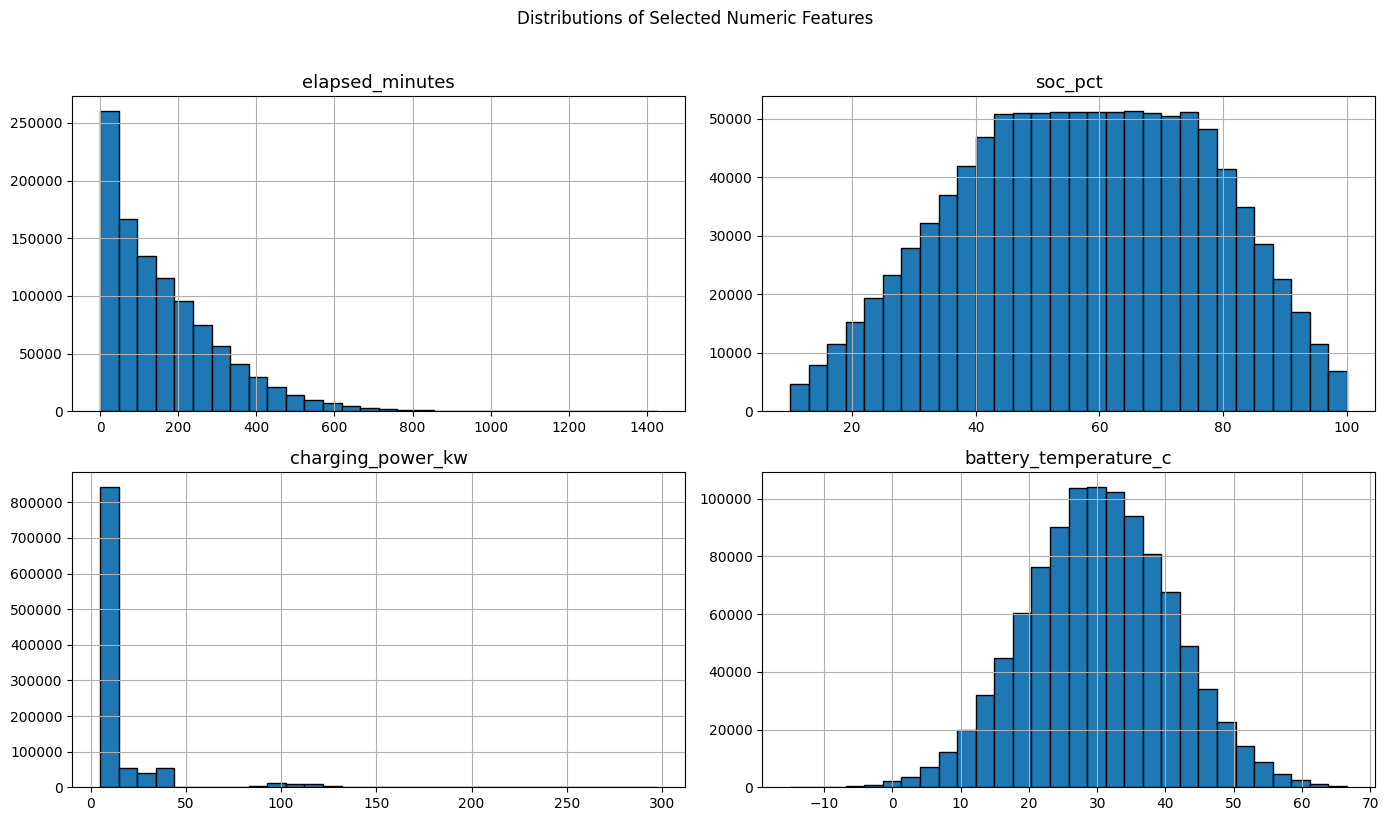

In [9]:
plot_cols = numeric_cols[:6]
if plot_cols:
    df[plot_cols].hist(bins=30, figsize=(14, 8), edgecolor="black")
    plt.suptitle("Distributions of Selected Numeric Features", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for histograms.")

## 10. Explore correlations between numeric features

Correlation can reveal related measurements and possible redundancy. It does not establish causation, and correlation values can be misleading when variables have strong outliers or nonlinear relationships.

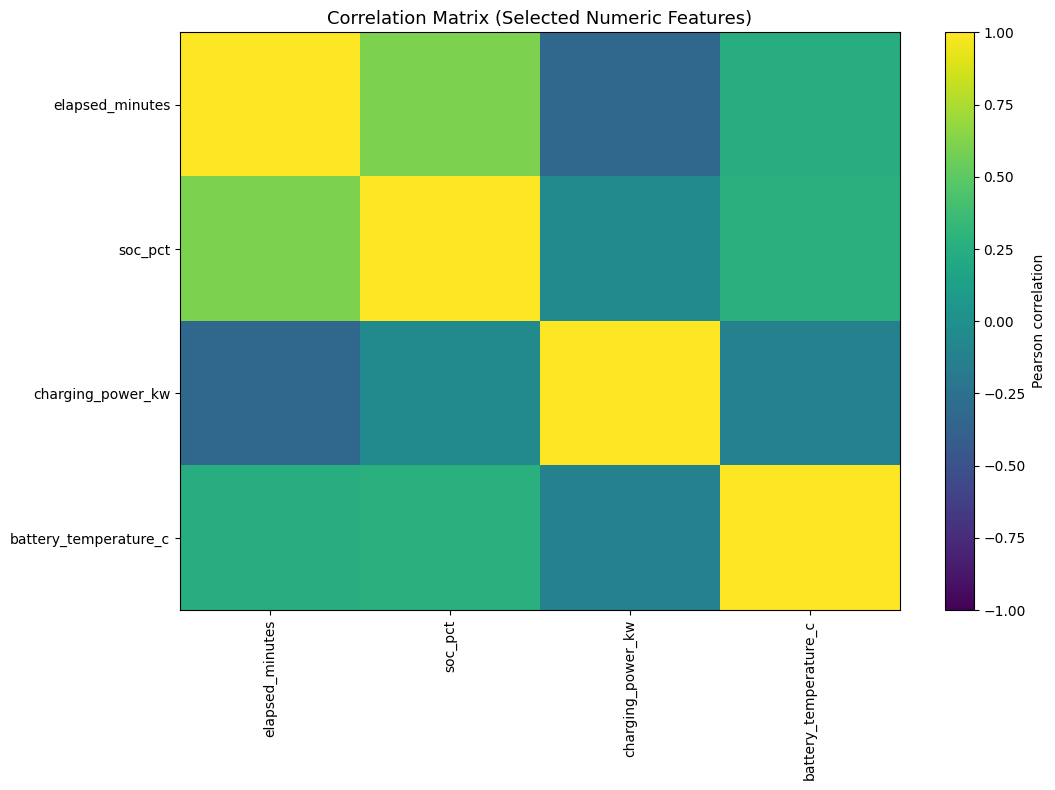

,elapsed_minutes,soc_pct,charging_power_kw,battery_temperature_c
elapsed_minutes,1.000,0.610,-0.330,0.250
soc_pct,0.610,1.000,-0.040,0.270
charging_power_kw,-0.330,-0.040,1.000,-0.120
battery_temperature_c,0.250,0.270,-0.120,1.000


In [10]:
corr_cols = [c for c in numeric_cols if df[c].nunique(dropna=True) > 1][:15]
if len(corr_cols) >= 2:
    corr = df[corr_cols].corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(11, 8))
    image = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.index)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticklabels(corr.index)
    ax.set_title("Correlation Matrix (Selected Numeric Features)")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    plt.tight_layout()
    plt.show()
    display(corr.round(2))
else:
    print("At least two varying numeric columns are needed for correlation analysis.")

## 11. Identify possible date or time columns

Timestamp fields enable temporal analyses such as sessions by hour, weekday, or month. The cell attempts safe datetime conversion on column names that look time-related and on object columns that can be parsed reliably.

In [11]:
time_candidates = [
    c for c in df.columns
    if any(token in c.lower() for token in ["date", "time", "timestamp", "datetime"])
]
datetime_cols = []

for col in time_candidates:
    parsed = pd.to_datetime(df[col], errors="coerce")
    valid_ratio = parsed.notna().mean() if len(parsed) else 0
    if valid_ratio >= 0.5:
        df[col] = parsed
        datetime_cols.append(col)

print("Datetime columns parsed:", datetime_cols if datetime_cols else "None detected")
if datetime_cols:
    for col in datetime_cols:
        print(f"{col}: {df[col].min()} to {df[col].max()}")

Datetime columns parsed: None detected


## 12. Analyze observations over time when possible

If a timestamp was detected, this cell visualizes record counts by month. Counts describe the dataset's coverage and should not be mistaken for real-world charging demand unless each row and the data collection process support that interpretation.

In [12]:
if datetime_cols:
    time_col = datetime_cols[0]
    time_series = df.dropna(subset=[time_col]).set_index(time_col).resample("MS").size()
    if len(time_series):
        ax = time_series.plot(kind="line", marker="o", figsize=(11, 4))
        ax.set_title(f"Records Over Time — {time_col}")
        ax.set_xlabel("Date")
        ax.set_ylabel("Number of records")
        plt.tight_layout()
        plt.show()
        display(time_series.rename("record_count").to_frame().tail(24))
    else:
        print("No valid timestamps available to aggregate.")
else:
    print("Temporal analysis skipped because no datetime column was detected.")

Temporal analysis skipped because no datetime column was detected.


## 13. Detect charging- and battery-related fields

Column names are searched for common EV domain terms. This is a convenience layer, not a guarantee that every matched field has the same unit or definition. Confirm units and meanings using the dataset's documentation before making operational conclusions.

In [13]:
domain_terms = {
    "charging": ["charge", "charging", "session", "charger", "station", "plug", "duration"],
    "energy_power": ["energy", "power", "kwh", "kw", "watt"],
    "battery": ["battery", "soc", "soh", "voltage", "current", "temperature", "cycle", "capacity"],
    "vehicle": ["vehicle", "ev", "car", "model", "make"],
    "cost": ["cost", "price", "fee", "revenue", "tariff"]
}

domain_columns = {}
for group, terms in domain_terms.items():
    matches = [c for c in df.columns if any(term in c.lower() for term in terms)]
    domain_columns[group] = matches
    print(f"{group.replace('_', ' ').title()}: {matches if matches else 'No matching columns'}")

Charging: ['session_id', 'station_id', 'charging_power_kw']
Energy Power: ['charging_power_kw']
Battery: ['soc_pct', 'battery_temperature_c']
Vehicle: ['vehicle_id']
Cost: No matching columns


## 14. Explore relationships between likely EV measurements

When at least two relevant numeric columns exist, the notebook draws a scatter plot using a likely energy/power/battery measurement pair. The selected columns are printed so the relationship is transparent; a plot is skipped if a suitable pair cannot be identified.

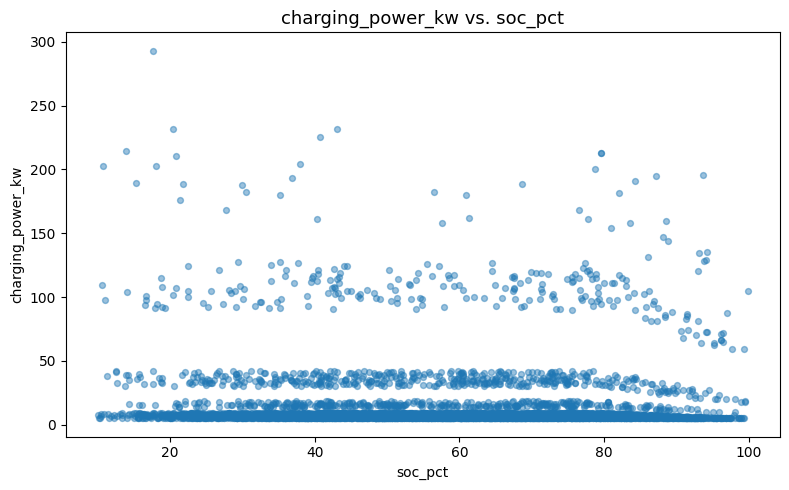

Plotted 5,000 observations.


In [14]:
preferred_tokens = ["energy", "power", "soc", "soh", "voltage", "current", "temperature", "duration", "capacity"]
preferred_numeric = [
    c for c in numeric_cols
    if any(token in c.lower() for token in preferred_tokens) and df[c].nunique(dropna=True) > 1
]

if len(preferred_numeric) >= 2:
    x_col, y_col = preferred_numeric[0], preferred_numeric[1]
    scatter_data = df[[x_col, y_col]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(scatter_data) > 5000:
        scatter_data = scatter_data.sample(5000, random_state=RANDOM_STATE)
    plt.figure(figsize=(8, 5))
    plt.scatter(scatter_data[x_col], scatter_data[y_col], alpha=0.45, s=18)
    plt.title(f"{y_col} vs. {x_col}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.tight_layout()
    plt.show()
    print(f"Plotted {len(scatter_data):,} observations.")
else:
    print("Not enough suitable numeric EV-related columns for a scatter plot.")

## 15. Build a lightweight data-quality summary

This compact summary can be retained in a report or README. It includes dimensions, duplicates, missingness, and the number of numeric, categorical, and datetime fields detected by the workflow.

In [15]:

# Dataset Summary

import pandas as pd
import numpy as np
from pathlib import Path

# Initialize the raw dataset if it does not exist
if "df_raw" not in globals():
    if "df" in globals():
        df_raw = df.copy()
    else:
        data_files = list(Path("/kaggle/input").rglob("*.csv"))

        if not data_files:
            raise FileNotFoundError(
                "No CSV dataset found. Attach your dataset using Kaggle's Add Input."
            )

        df_raw = pd.read_csv(data_files[0], low_memory=False)
        print(f"Loaded dataset: {data_files[0].name}")

# Initialize the working dataset
if "df" not in globals():
    df = df_raw.copy()

# Initialize the cleaned dataset
if "df_clean" not in globals():
    df_clean = df.drop_duplicates().copy()

# Detect datetime columns if the variable does not exist
if "datetime_cols" not in globals():
    datetime_cols = [
        col for col in df_clean.columns
        if any(term in col.lower() for term in ["date", "time", "timestamp", "datetime"])
        and pd.api.types.is_datetime64_any_dtype(df_clean[col])
    ]

# Create the summary
summary = pd.DataFrame({
    "metric": [
        "Rows in raw table",
        "Columns in raw table",
        "Rows after duplicate removal",
        "Exact duplicate rows removed",
        "Columns with missing values",
        "Numeric columns",
        "Categorical/text columns",
        "Datetime columns"
    ],
    "value": [
        len(df_raw),
        df_raw.shape[1],
        len(df_clean),
        len(df) - len(df_clean),
        int((df_clean.isna().sum() > 0).sum()),
        len(df_clean.select_dtypes(include=np.number).columns),
        len(df_clean.select_dtypes(include=["object", "category", "bool"]).columns),
        len(datetime_cols)
    ]
})

display(summary)

if "main_path" in globals():
    print("\nAnalysis table selected:", Path(main_path).name)
else:
    print("\nDataset summary generated successfully.")

,metric,value
0,Rows in raw table,1039402
1,Columns in raw table,7
2,Rows after duplicate removal,1039402
3,Exact duplicate rows removed,0
4,Columns with missing values,0
5,Numeric columns,4
6,Categorical/text columns,3
7,Datetime columns,0



Analysis table selected: ev_charging_telemetry.csv


## 16. Optional baseline modeling: find a plausible target

A predictive model is only meaningful when the dataset contains a well-defined target variable. This cell searches for common battery health, charging duration, energy, cost, and status labels. It does **not** assume that a particular target exists; review the printed candidate before using the model section.

In [16]:
target_keywords = [
    "soh", "state_of_health", "battery_health", "health_score",
    "charging_duration", "duration", "energy_consumed", "energy_kwh",
    "charging_cost", "cost", "failure", "status", "target", "label"
]

target_candidates = [
    c for c in df_clean.columns
    if any(keyword in c.lower().replace(" ", "_") for keyword in target_keywords)
    and df_clean[c].nunique(dropna=True) > 1
    and df_clean[c].nunique(dropna=True) < max(2, int(0.95 * len(df_clean)))
]

print("Potential target columns (review meaning and units before modeling):")
print(target_candidates if target_candidates else "No clear target candidate found.")
print("\nThis notebook will use the first candidate only as an optional baseline.")

Potential target columns (review meaning and units before modeling):
No clear target candidate found.

This notebook will use the first candidate only as an optional baseline.


## 17. Export summary and conclude

This final section exports compact reports to the Kaggle working directory. Run all cells from top to bottom, then save a new notebook version so the executed outputs and Matplotlib visualizations are stored with that version.

In [17]:
output_dir = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
output_dir.mkdir(parents=True, exist_ok=True)

schema.to_csv(output_dir / "ev_dataset_schema.csv", index=False)
missing.rename_axis("column").reset_index().to_csv(output_dir / "ev_missingness_report.csv", index=False)

summary = pd.DataFrame({
    "metric": ["rows", "columns", "numeric_columns", "categorical_columns",
               "datetime_columns", "columns_with_missing_values", "duplicate_rows_in_clean_copy"],
    "value": [len(df_clean), df_clean.shape[1],
              len(df_clean.select_dtypes(include=np.number).columns),
              len(df_clean.select_dtypes(include=["object", "category", "bool"]).columns),
              len(datetime_cols), int((df_clean.isna().sum() > 0).sum()),
              int(df_clean.duplicated().sum())]
})
summary.to_csv(output_dir / "ev_analysis_summary.csv", index=False)
display(summary)

print("\nExported reports:")
for filename in ["ev_dataset_schema.csv", "ev_missingness_report.csv", "ev_analysis_summary.csv"]:
    print("-", output_dir / filename)

print("\nConclusion:")
print("- Review the plots and data dictionary before drawing domain conclusions.")
print("- Verify target meaning and avoid leakage before supervised modeling.")
print("- Consider time- or vehicle-aware validation for realistic evaluation.")
print("- After running all cells, save a new Kaggle notebook version to preserve outputs.")

,metric,value
0,rows,1039402
1,columns,7
2,numeric_columns,4
3,categorical_columns,3
4,datetime_columns,0
5,columns_with_missing_values,0
6,duplicate_rows_in_clean_copy,0



Exported reports:
- /kaggle/working/ev_dataset_schema.csv
- /kaggle/working/ev_missingness_report.csv
- /kaggle/working/ev_analysis_summary.csv

Conclusion:
- Review the plots and data dictionary before drawing domain conclusions.
- Verify target meaning and avoid leakage before supervised modeling.
- Consider time- or vehicle-aware validation for realistic evaluation.
- After running all cells, save a new Kaggle notebook version to preserve outputs.
